<a href="https://colab.research.google.com/github/JyRaGa/CS303-Machine-Learning_Coursework/blob/main/exp13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS303 Machine Learning Lab
## Experiment No. 13: End-to-End Mini-Project and Responsible-ML Audit
### Roll No: 24/CS/232

---

### **Aim:**
To implement an **end-to-end machine-learning pipeline** covering data ingestion, preprocessing, feature engineering, model selection, hyperparameter tuning, evaluation, error analysis, reproducibility, and **responsible-ML auditing**.

### **Objectives:**
After completing this experiment, students will be able to:
1. **Formulate** a machine-learning problem and propose a testable hypothesis.
2. **Build** an end-to-end pipeline using Scikit-learn.
3. **Perform** preprocessing and feature engineering without data leakage.
4. **Compare** models using cross-validation and hyperparameter tuning.
5. **Analyse** misclassified examples and model weaknesses.
6. **Evaluate** performance across demographic or sensitive subgroups.
7. **Identify** fairness concerns and test possible interventions.
8. **Save** a trained model and document the software environment for reproducibility.
9. **Communicate** project findings through a report and presentation.

### **Pseudo Algorithm / Steps:**
1. **Start**
2. **Load** the selected dataset.
3. **Identify** the target variable and sensitive attributes.
4. **Inspect** the dataset for missing values, duplicates, and inconsistent values.
5. **Separate** input features and target labels.
6. **Preserve** sensitive attributes for later subgroup evaluation.
7. **Split** the data into training and testing sets.
8. **Define** numerical and categorical preprocessing operations.
9. **Create** a preprocessing pipeline.
10. **Select** candidate machine-learning models.
11. **Define** hyperparameter grids for the candidate models.
12. **Apply** cross-validation using `GridSearchCV`.
13. **Select** the best model based on the chosen evaluation metric.
14. **Evaluate** the final model on the held-out test set.
15. **Identify** misclassified examples.
16. **Perform** subgroup performance evaluation.
17. **Identify** potential fairness gaps.
18. **Apply** at least one fairness intervention.
19. **Compare** the original and modified model results.
20. **Save** the final pipeline and record software versions.
21. **Prepare** the final report and presentation.
22. **Stop**

**1. Problem Formulation & Hypothesis (Objective 1)**

* **Mini-project:** **Bitcoin Transaction Fee Prediction**, using three years of daily Bitcoin network data.
* **Problem:** predict **tomorrow's average transaction fee** from what is known today (regression). The prediction is then turned into a **high-fee / normal day** decision (is the predicted fee above the median of the last 14 days?), so a user can decide to send now or wait.
* **Why the log of the fee:** the raw fee is badly skewed (median about \$1, maximum \$128), so a few spike days would dominate a model trained on dollars. The model predicts $\ln(\text{fee})$; an error of 0.10 in logs means roughly a 10% error in the fee.
* **Hypothesis H1:** a tuned model beats the naive forecast "tomorrow's fee = today's fee" by at least 10% in mean absolute error.
* **Hypothesis H2:** fees dip on weekends, so the model will behave differently on weekends than on weekdays (different error and different high-fee recall), which the subgroup audit should detect.
* **Metric:** **MAE on the log fee** is used for model selection because it is not blown up by a few spike days; RMSE and $R^2$ are also reported.

**2. Loading the Dataset & Identifying Target and Sensitive Attributes (Steps 2–3)**

* **Dataset:** daily Bitcoin network data from the Blockchain.com Charts API (17 Nov 2023 – 15 Nov 2026), read from the course GitHub repo so it opens in Colab without an upload.
* **Target:** `ln_fee` $= \ln(\texttt{avg_fee_usd})$ of the day being predicted (Continuous variable $\rightarrow$ Regression Task). `med14`, the median fee of the previous 14 days, is the reference for the high-fee decision; the first 14 days have no full window and are dropped.
* **Sensitive attributes:** the data has no people, so the audit groups are the conditions a user transacts in: `day_type` (Weekday / Weekend) and `backlog` (Busy / Calm: yesterday's mempool above or below its own 14-day median).
* **Features:** numerical `avg_fee_usd`, `n_tx`, `mempool_mb`, `price_usd`, `hash_rate_ehs`, `block_size_mb`; binary `weekend`; `total_fees_usd` is not used because `avg_fee_usd = total_fees_usd / n_tx`, i.e. it contains the answer.

In [1]:
import json
import platform
import warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_squared_error,
                             precision_score, r2_score, recall_score)
from sklearn.model_selection import (GridSearchCV, TimeSeriesSplit,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
warnings.filterwarnings('ignore')
url = ('https://raw.githubusercontent.com/JyRaGa/CS303-Machine-Learning_Coursework'
       '/refs/heads/main/datasets/btc_fees_daily.csv')
df = pd.read_csv(url, parse_dates=['date'])
n_raw = len(df)
df['med14'] = df['avg_fee_usd'].shift(1).rolling(14).median()
mem = df['mempool_mb'].shift(1)
df['backlog'] = np.where(mem > mem.rolling(14).median(), 'Busy', 'Calm')
df = df.dropna(subset=['med14']).reset_index(drop=True)
df['ln_fee'] = np.log(df['avg_fee_usd'])
df['day_type'] = np.where(df['weekend'] == 1, 'Weekend', 'Weekday')
target, sensitive = 'ln_fee', ['day_type', 'backlog']
print('raw rows:', n_raw, '| rows with a 14-day window:', df.shape[0])
show = ['date', 'avg_fee_usd', 'mempool_mb', 'n_tx', 'med14', 'ln_fee', 'backlog',
        'day_type']
print(df[show].head().round(3).to_string())
print('\nfee in usd:\n', df['avg_fee_usd'].describe().round(3).to_string())

raw rows: 1092 | rows with a 14-day window: 1078
        date  avg_fee_usd  mempool_mb    n_tx  med14  ln_fee backlog day_type
0 2023-12-01        7.642     262.283  496468  8.684   2.034    Busy  Weekday
1 2023-12-02        5.853     226.716  429362  7.329   1.767    Busy  Weekend
2 2023-12-03        7.918     242.424  707876  6.858   2.069    Calm  Weekend
3 2023-12-04       10.986     243.565  570395  6.858   2.397    Busy  Weekday
4 2023-12-05       19.455     250.555  514962  6.858   2.968    Busy  Weekday

fee in usd:
 count    1078.000
mean        2.833
std         6.520
min         0.156
25%         0.485
50%         1.030
75%         2.202
max       128.447


**3. Inspecting Missing Values, Duplicates & Inconsistent Values (Step 4)**

* **Missing values / duplicates:** counted per column; duplicate rows and duplicate dates are checked.
* **Inconsistent values:** gaps in the calendar, zero or negative readings, and whether the `weekend` flag agrees with the date.
* **Feature engineering:** every input is **yesterday's** value (`shift(1)`), so the model never sees the day it is predicting. Logs are taken because the raw series are right-skewed. `fee_chg` and `mempool_chg` are one-day log changes, and `fee_vs_med` is how far yesterday's fee was from the 14-day median.
* A row that comes right after a calendar gap has no real "yesterday", so its lag features are set to missing and left for the imputer.

In [2]:
raw = ['avg_fee_usd', 'mempool_mb', 'n_tx', 'price_usd', 'hash_rate_ehs',
       'block_size_mb']
print('missing values :', int(df[raw].isna().sum().sum()))
print('duplicate rows :', df.duplicated().sum(), '| duplicate dates:',
      df['date'].duplicated().sum())
gap = df['date'].diff().dt.days
print('calendar gaps  :', df.loc[gap > 1, 'date'].dt.date.astype(str).tolist(),
      '| days skipped:', int((gap[gap > 1] - 1).sum()))
print('values <= 0    :', int((df[raw] <= 0).sum().sum()))
print('weekend flag ok:', (df['weekend'] == (df['date'].dt.dayofweek >= 5)).all())
print('fee skew       :', round(df['avg_fee_usd'].skew(), 2), '-> log fee:',
      round(df['ln_fee'].skew(), 2))
lg = np.log(df[raw])
lag = lg.shift(1)
lag.columns = ['fee_lag', 'mempool_lag', 'n_tx_lag', 'price_lag', 'hash_lag',
               'block_lag']
lag['fee_chg'] = lg['avg_fee_usd'].diff().shift(1)
lag['mempool_chg'] = lg['mempool_mb'].diff().shift(1)
lag['fee_vs_med'] = lag['fee_lag'] - np.log(df['med14'])
lag[gap > 1] = np.nan  # no real yesterday after a gap
df = df.join(lag)
df['day_name'] = df['date'].dt.day_name().str[:3]
print('\nrows with missing lag features:', int(lag.isna().any(axis=1).sum()))
print('median fee by day (usd):')
print(df.groupby('day_name')['avg_fee_usd'].median().round(2).to_frame().T
      .to_string(index=False))

missing values : 0
duplicate rows : 0 | duplicate dates: 0
calendar gaps  : ['2025-11-16'] | days skipped: 3
values <= 0    : 0
weekend flag ok: True
fee skew       : 9.81 -> log fee: 0.77

rows with missing lag features: 3
median fee by day (usd):
 Fri  Mon  Sat  Sun  Thu  Tue  Wed
1.22 1.04 0.99 0.81 1.12 1.05 1.13


**4. Separating Features, Preserving Sensitive Attributes & Train-Test Split (Steps 5–7)**

* `X` holds the model inputs and `y` the target; `date`, the same-day readings and `total_fees_usd` are left out.
* A separate copy `S` of `day_type` and `backlog` is kept **row-aligned** with `X`, so subgroup metrics can be computed later even if the model changes.
* **Split:** 80/20 **in time order** (`shuffle=False`): the first 80% of days train the model and the last 20% test it. A random split would let the model learn from days that come after the ones it is tested on.

In [3]:
num_cols = lag.columns.tolist()
cat_cols = ['day_name']
X, y = df[num_cols + cat_cols], df[target]
S = df[sensitive].copy()  # kept aside for the audit
X_train, X_test, y_train, y_test, S_train, S_test = train_test_split(
    X, y, S, test_size=0.2, shuffle=False)
d = df['date'].dt.date
print('train:', X_train.shape, d[X_train.index[0]], 'to', d[X_train.index[-1]])
print('test :', X_test.shape, d[X_test.index[0]], 'to', d[X_test.index[-1]])
for nm, yy in [('train', y_train), ('test ', y_test)]:
    print(f'{nm} fee range (usd): {np.exp(yy.min()):.2f} to '
          f'{np.exp(yy.max()):.2f}, median {np.exp(yy.median()):.2f}')
print('test set group sizes:', S_test['day_type'].value_counts().to_dict(),
      S_test['backlog'].value_counts().to_dict())

train: (862, 10) 2023-12-01 to 2026-04-13
test : (216, 10) 2026-04-14 to 2026-11-15
train fee range (usd): 0.16 to 128.45, median 1.35
test  fee range (usd): 0.16 to 0.86, median 0.34
test set group sizes: {'Weekday': 154, 'Weekend': 62} {'Calm': 113, 'Busy': 103}


**5. Numerical & Categorical Preprocessing Pipeline (Steps 8–9)**

* **Numerical:** median imputation $\rightarrow$ `StandardScaler`.
* **Categorical:** most-frequent imputation $\rightarrow$ `OneHotEncoder(handle_unknown='ignore')` on the day of the week (known in advance for the day being predicted).
* Both are joined in a `ColumnTransformer`; because it sits **inside the model pipeline**, every CV fold fits the imputers, scaler and encoder on its own training part only, so there is **no data leakage**.

In [4]:
num_pipe = Pipeline([('impute', SimpleImputer(strategy='median')),
                     ('scale', StandardScaler())])
cat_pipe = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                     ('onehot', OneHotEncoder(handle_unknown='ignore'))])
prep = ColumnTransformer([('num', num_pipe, num_cols),
                          ('cat', cat_pipe, cat_cols)])
n_out = prep.fit(X_train).transform(X_train).shape[1]
print('features after preprocessing:', n_out)
names = [n.split('__')[1] for n in prep.get_feature_names_out()]
for i in range(0, n_out, 6):
    print(' ', ', '.join(names[i:i + 6]))

features after preprocessing: 16
  fee_lag, mempool_lag, n_tx_lag, price_lag, hash_lag, block_lag
  fee_chg, mempool_chg, fee_vs_med, day_name_Fri, day_name_Mon, day_name_Sat
  day_name_Sun, day_name_Thu, day_name_Tue, day_name_Wed


**6. Candidate Models, Hyperparameter Grids & GridSearchCV (Steps 10–13)**

* **Candidates:** Ridge Regression (regularised linear model), Random Forest (bagging) and Gradient Boosting (boosting).
* Each candidate is put in `Pipeline([prep, model])` and tuned by `GridSearchCV` with `scoring='neg_mean_absolute_error'`.
* **CV scheme:** `TimeSeriesSplit(n_splits=5)`, where each fold trains on the past and validates on the block of days right after it, so validation is never older than training.
* The model with the **lowest mean CV MAE** is selected; the test set is not touched here.

In [5]:
cv = TimeSeriesSplit(n_splits=5)
models = {
    'Ridge Regression': (Ridge(), {'reg__alpha': [0.1, 1, 10, 100]}),
    'Random Forest': (RandomForestRegressor(random_state=42),
                      {'reg__n_estimators': [100, 300],
                       'reg__max_depth': [4, 6, None],
                       'reg__min_samples_leaf': [1, 5]}),
    'Gradient Boosting': (GradientBoostingRegressor(random_state=42),
                          {'reg__n_estimators': [100, 200],
                           'reg__learning_rate': [0.05, 0.1],
                           'reg__max_depth': [2, 3]})}
searches, rows = {}, []
for name, (reg, grid) in models.items():
    gs = GridSearchCV(Pipeline([('prep', prep), ('reg', reg)]), grid, cv=cv,
                      scoring='neg_mean_absolute_error', n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    i = gs.best_index_
    best = {k.replace('reg__', ''): v for k, v in gs.best_params_.items()}
    rows.append([name, -gs.cv_results_['mean_test_score'][i],
                 gs.cv_results_['std_test_score'][i]])
    print(f'{name:<18}: {best}')
cv_df = pd.DataFrame(rows, columns=['Model', 'CV MAE', 'Std'])
cv_df = cv_df.sort_values('CV MAE')
print('\n' + cv_df.round(4).to_string(index=False))
best_name = cv_df.iloc[0]['Model']
best_model = searches[best_name].best_estimator_
print('\nselected model:', best_name)

Ridge Regression  : {'alpha': 0.1}
Random Forest     : {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 300}
Gradient Boosting : {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}

            Model  CV MAE    Std
 Ridge Regression  0.2875 0.1240
Gradient Boosting  0.4544 0.2994
    Random Forest  0.4706 0.2692

selected model: Ridge Regression


**7. Evaluating the Final Model on the Held-Out Test Set (Step 14)**

* The selected pipeline is scored once on the unseen last 20% of days with MAE, RMSE and $R^2$ on the log fee, and MAE in dollars.
* It is compared with two **naive baselines** that need no machine learning: "tomorrow = today", and "today + the usual change for that weekday" (learnt from the training days). A model is only useful if it beats these.

FINAL MODEL: RIDGE REGRESSION (TEST SET)
                           mae    rmse      r2  mae_usd
Naive: same as today    0.2631  0.3390 -0.1794   0.0966
Naive: today + weekday  0.2097  0.2760  0.2182   0.0791
Ridge Regression        0.2096  0.2649  0.2796   0.0783
Random Forest           0.2232  0.2923  0.1227   0.0834
Gradient Boosting       0.2867  0.3483 -0.2454   0.1153
mae vs naive: 20.3% lower | vs weekday naive: 0.0% lower


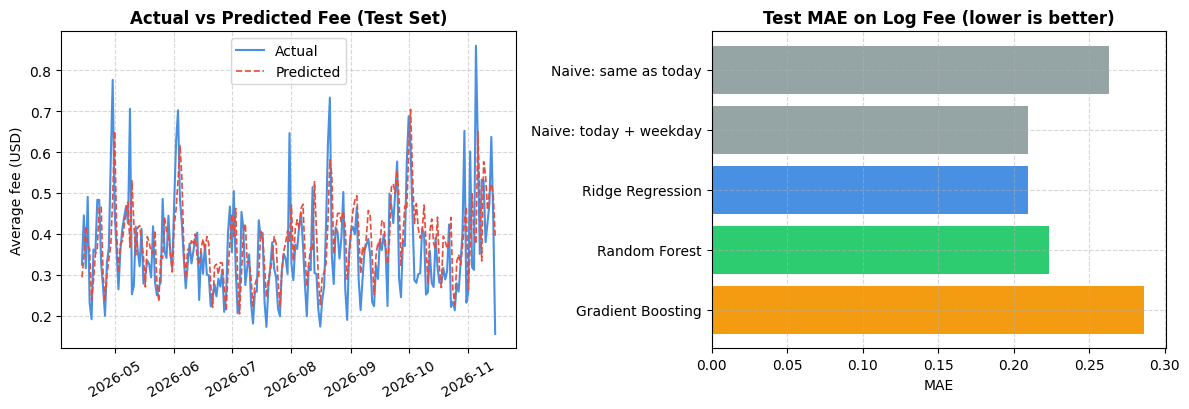

In [6]:
def scores(y_true, pred):
    return {'mae': mean_absolute_error(y_true, pred),
            'rmse': np.sqrt(mean_squared_error(y_true, pred)),
            'r2': r2_score(y_true, pred),
            'mae_usd': mean_absolute_error(np.exp(y_true), np.exp(pred))}
pred_test = best_model.predict(X_test)
test_res = scores(y_test, pred_test)
dow_chg = (y_train - X_train['fee_lag']).groupby(X_train['day_name']).mean()
preds = {'Naive: same as today': X_test['fee_lag'],
         'Naive: today + weekday': X_test['fee_lag']
         + X_test['day_name'].map(dow_chg)}
preds.update({k: gs.predict(X_test) for k, gs in searches.items()})
res_df = pd.DataFrame({k: scores(y_test, v) for k, v in preds.items()}).T
print('=' * 62)
print(f'FINAL MODEL: {best_name.upper()} (TEST SET)')
print('=' * 62)
print(res_df.round(4).to_string())
print('=' * 62)
naive_mae = res_df['mae'].iloc[0]
gain = 1 - test_res['mae'] / naive_mae
gain2 = 1 - test_res['mae'] / res_df['mae'].iloc[1]
print(f'mae vs naive: {gain:.1%} lower | vs weekday naive: {gain2:.1%} lower')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
dates = df.loc[X_test.index, 'date']
axes[0].plot(dates, np.exp(y_test), color='#4a90e2', lw=1.5, label='Actual')
axes[0].plot(dates, np.exp(pred_test), color='#e74c3c', lw=1.2, ls='--',
             label='Predicted')
axes[0].set_title('Actual vs Predicted Fee (Test Set)', fontsize=12,
                  fontweight='bold')
axes[0].set_ylabel('Average fee (USD)')
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend()
cols = ['#95a5a6', '#95a5a6', '#4a90e2', '#2ecc71', '#f39c12']
axes[1].barh(res_df.index[::-1], res_df['mae'][::-1], color=cols[::-1])
axes[1].set_title('Test MAE on Log Fee (lower is better)', fontsize=12,
                  fontweight='bold')
axes[1].set_xlabel('MAE')
for ax in axes:
    ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**8. Error Analysis: Misclassified Examples (Step 15)**

* The days with the **largest prediction errors** are listed with the actual and predicted fee.
* The forecast is then turned into a decision: a day is predicted **high-fee** when the predicted fee is above `med14`, and it is actually high-fee when the real fee is. The confusion matrix splits the wrong decisions into **false positives** (predicted high fee, day was normal) and **false negatives** (predicted normal, fee was high).

largest errors (resid = actual - predicted log fee):
      date day_name backlog  avg_fee_usd  pred_usd  resid
2026-11-15      Sun    Busy        0.156     0.393 -0.924
2026-11-05      Thu    Calm        0.860     0.376  0.828
2026-05-10      Sun    Busy        0.253     0.530 -0.740
2026-10-31      Sat    Busy        0.232     0.466 -0.698
2026-10-23      Fri    Calm        0.221     0.441 -0.688
2026-05-09      Sat    Busy        0.706     0.368  0.652
2026-08-13      Thu    Busy        0.304     0.528 -0.551
2026-07-31      Fri    Busy        0.646     0.382  0.526

mean residual: -0.0916 | under-predicted days: 71 of 216

high-fee decision: accuracy 0.7546 | false positives: 47 | false negatives: 6
wrong decisions by group:
{'Weekday': 0.234, 'Weekend': 0.274}
{'Busy': 0.194, 'Calm': 0.292}


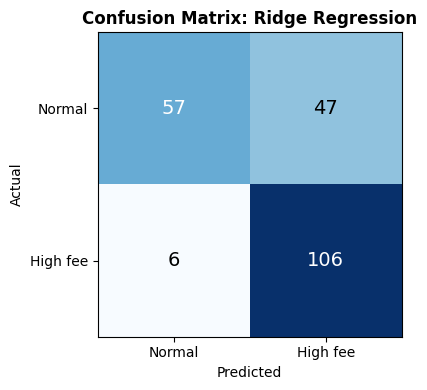

In [7]:
ln_med = np.log(df.loc[X_test.index, 'med14']).values
margin = pred_test - ln_med  # predicted log gap to the 14-day median
high_test = (y_test.values > ln_med).astype(int)
pred_high = (margin > 0).astype(int)
resid = y_test.values - pred_test
err = df.loc[X_test.index].assign(pred_usd=np.exp(pred_test), resid=resid,
                                  actual=high_test, pred=pred_high)
err['date'] = err['date'].dt.date
cols = ['date', 'day_name', 'backlog', 'avg_fee_usd', 'pred_usd', 'resid']
big = err['resid'].abs().sort_values(ascending=False).index[:8]
print('largest errors (resid = actual - predicted log fee):')
print(err.loc[big, cols].round(3).to_string(index=False))
print('\nmean residual:', round(resid.mean(), 4), '| under-predicted days:',
      int((resid > 0).sum()), 'of', len(resid))
cm = confusion_matrix(high_test, pred_high)
tn, fp, fn, tp = cm.ravel()
acc0 = accuracy_score(high_test, pred_high)
print(f'\nhigh-fee decision: accuracy {acc0:.4f} | false positives: {fp} | '
      f'false negatives: {fn}')
print('wrong decisions by group:')
for g in sensitive:
    print(err.assign(wrong=err['actual'] != err['pred'])
             .groupby(g)['wrong'].mean().round(3).to_dict())
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=14,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xticks([0, 1], ['Normal', 'High fee'])
ax.set_yticks([0, 1], ['Normal', 'High fee'])
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title(f'Confusion Matrix: {best_name}', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**9. Subgroup Performance Evaluation & Fairness Gaps (Steps 16–17)**

* Metrics are recomputed separately for each `day_type` and `backlog` group on the test set.
* **MAE** and **bias** (mean of actual − predicted) show whether the forecast is equally accurate for each group. For the high-fee decision, **selection rate** $P(\hat{y}=1 \mid g)$ checks **demographic parity**, and **TPR** (recall) and **FPR** check **equal opportunity / equalised odds**.
* A rate gap of more than **0.10** between groups is flagged as a potential fairness concern: the model would be serving one kind of day worse than the other.

           Group   n   MAE   Bias  Base rate  Sel. rate   TPR   FPR
day_type=Weekday 154 0.189 -0.050      0.662      0.844 0.961 0.615
day_type=Weekend  62 0.261 -0.196      0.161      0.371 0.800 0.288
    backlog=Busy 103 0.222 -0.117      0.641      0.796 0.970 0.486
    backlog=Calm 113 0.198 -0.069      0.407      0.628 0.913 0.433

fairness gaps (max - min across groups):
day_type MAE gap      : 0.072 
day_type Sel. rate gap: 0.473 <- flagged
day_type TPR gap      : 0.161 <- flagged
day_type FPR gap      : 0.327 <- flagged
backlog MAE gap       : 0.025 
backlog Sel. rate gap : 0.168 <- flagged
backlog TPR gap       : 0.057 
backlog FPR gap       : 0.054 


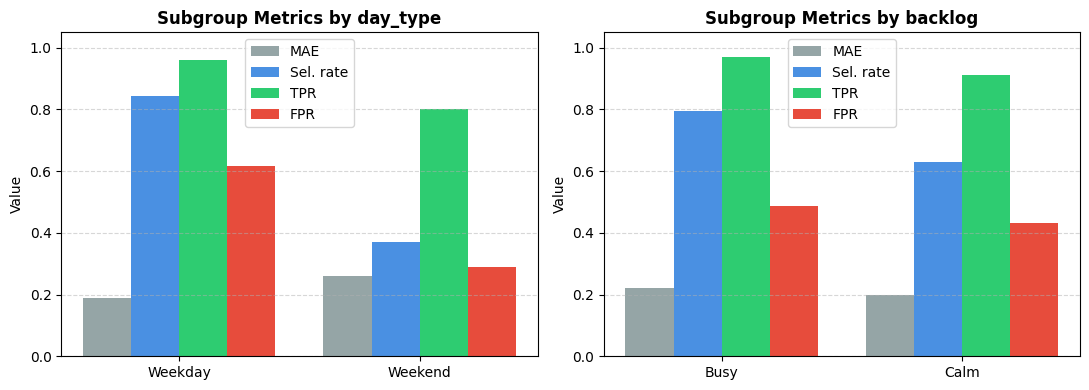

In [8]:
def group_table(pred):
    out = []
    for g in sensitive:
        for val in sorted(S_test[g].unique()):
            m = (S_test[g] == val).values
            yt, yp = high_test[m], pred[m]
            fpr = ((yp == 1) & (yt == 0)).sum() / max((yt == 0).sum(), 1)
            out.append([f'{g}={val}', m.sum(), np.abs(resid[m]).mean(),
                        resid[m].mean(), yt.mean(), yp.mean(),
                        recall_score(yt, yp, zero_division=0), fpr])
    cols = ['Group', 'n', 'MAE', 'Bias', 'Base rate', 'Sel. rate', 'TPR', 'FPR']
    return pd.DataFrame(out, columns=cols)
def gaps(tab):
    res = {}
    for g in sensitive:
        t = tab[tab['Group'].str.startswith(g)]
        for c in ['MAE', 'Sel. rate', 'TPR', 'FPR']:
            res[f'{g} {c} gap'] = t[c].max() - t[c].min()
    return res
orig_tab = group_table(pred_high)
print(orig_tab.round(3).to_string(index=False))
orig_gaps = gaps(orig_tab)
print('\nfairness gaps (max - min across groups):')
for k, v in orig_gaps.items():
    print(f'{k:<22}: {v:.3f}',
          '<- flagged' if v > 0.10 and 'MAE' not in k else '')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, g in zip(axes, sensitive):
    t = orig_tab[orig_tab['Group'].str.startswith(g)]
    xs = np.arange(len(t))
    for k, (c, col) in enumerate(zip(['MAE', 'Sel. rate', 'TPR', 'FPR'],
                                     ['#95a5a6', '#4a90e2', '#2ecc71',
                                      '#e74c3c'])):
        ax.bar(xs + (k - 1.5) * 0.2, t[c], 0.2, color=col, label=c)
    ax.set_xticks(xs, t['Group'].str.split('=').str[1])
    ax.set_ylim(0, 1.05)
    ax.set_title(f'Subgroup Metrics by {g}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Value')
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.legend()
plt.tight_layout()
plt.show()

**10. Fairness Intervention: Group-Specific Thresholds (Steps 18–19)**

* The decision rule is "high fee if the predicted log gap to `med14` is above a threshold"; the original threshold is 0.
* **Intervention:** post-processing with a **separate threshold per `day_type`**, chosen so that weekdays and weekends reach the same **TPR** (equal opportunity) as the overall model.
* The thresholds are chosen from **out-of-fold predictions on the training set** (the same time-ordered folds, each predicted by a model trained only on earlier days), so the test set is still unseen.
* First a single threshold is swept to show how precision and recall trade off; then the original and modified decisions are compared. The fee forecast itself (and its MAE) is not changed by this step.

In [9]:
def dec_scores(pred):
    return {'accuracy': accuracy_score(high_test, pred),
            'precision': precision_score(high_test, pred, zero_division=0),
            'recall': recall_score(high_test, pred),
            'f1': f1_score(high_test, pred)}
sweep = [[t, *dec_scores((margin > t).astype(int)).values()]
         for t in [-0.10, -0.05, 0.0, 0.05, 0.10]]
print(pd.DataFrame(sweep, columns=['Threshold', 'Accuracy', 'Precision',
                                   'Recall', 'F1']).round(4).to_string(index=False))
oof = np.full(len(y_train), np.nan)
for tr, va in cv.split(X_train):
    m_fold = clone(best_model).fit(X_train.iloc[tr], y_train.iloc[tr])
    oof[va] = m_fold.predict(X_train.iloc[va])
have = ~np.isnan(oof)  # the first block is never a validation fold
ln_med_tr = np.log(df.loc[X_train.index, 'med14']).values
oof_margin = oof - ln_med_tr
high_tr = (y_train.values > ln_med_tr).astype(int)
goal = recall_score(high_tr[have], (oof_margin[have] > 0).astype(int))
thr = {}
for g in ['Weekday', 'Weekend']:
    m = have & (S_train['day_type'] == g).values
    pos = np.sort(oof_margin[m & (high_tr == 1)])[::-1]
    thr[g] = pos[int(np.ceil(goal * len(pos))) - 1] - 1e-9  # tpr ~ goal
print(f'\ntarget tpr {goal:.3f} -> thresholds:',
      {k: round(float(v), 3) for k, v in thr.items()})
pred_fair = (margin > S_test['day_type'].map(thr).values).astype(int)
fair_tab = group_table(pred_fair)
fair_gaps = gaps(fair_tab)
dec_res, fair_res = dec_scores(pred_high), dec_scores(pred_fair)
cmp = pd.DataFrame({'Original (0)': {**dec_res, **orig_gaps},
                    'Group thresholds': {**fair_res, **fair_gaps}})
cmp['Change'] = cmp.iloc[:, 1] - cmp.iloc[:, 0]
print(cmp[~cmp.index.str.contains('MAE')].round(4).to_string())

 Threshold  Accuracy  Precision  Recall     F1
     -0.10    0.6481     0.5957  1.0000 0.7467
     -0.05    0.7083     0.6485  0.9554 0.7726
      0.00    0.7546     0.6928  0.9464 0.8000
      0.05    0.8009     0.7594  0.9018 0.8245
      0.10    0.7639     0.7905  0.7411 0.7650

target tpr 0.673 -> thresholds: {'Weekday': 0.029, 'Weekend': -0.069}
                        Original (0)  Group thresholds  Change
accuracy                      0.7546            0.7639  0.0093
precision                     0.6928            0.7047  0.0119
recall                        0.9464            0.9375 -0.0089
f1                            0.8000            0.8046  0.0046
day_type Sel. rate gap        0.4732            0.3793 -0.0938
day_type TPR gap              0.1608            0.0412 -0.1196
day_type FPR gap              0.3269            0.1923 -0.1346
backlog Sel. rate gap         0.1678            0.2218  0.0540
backlog TPR gap               0.0567            0.1153  0.0586
backlog FPR gap  

**11. Saving the Final Pipeline & Recording Software Versions (Step 20)**

* The whole fitted pipeline (preprocessing + model) is saved with `joblib`, so a row of lag features can be fed in directly.
* The group thresholds, selected parameters, metrics and library versions are saved in a metadata JSON for **reproducibility**.
* The saved model is reloaded and re-scored to prove it gives identical predictions.

In [10]:
joblib.dump(best_model, 'btc_fee_pipeline.pkl')
meta = {'model': best_name, 'params': searches[best_name].best_params_,
        'target': 'ln(avg_fee_usd) of the next day',
        'cv_mae': float(cv_df.iloc[0]['CV MAE']),
        'test_metrics': {k: round(float(v), 4) for k, v in test_res.items()},
        'day_thresholds': {k: round(float(v), 4) for k, v in thr.items()},
        'random_state': 42, 'python': platform.python_version(),
        'versions': {'sklearn': sklearn.__version__, 'numpy': np.__version__,
                     'pandas': pd.__version__, 'joblib': joblib.__version__}}
with open('btc_fee_metadata.json', 'w') as f:
    json.dump(meta, f, indent=2, default=str)
loaded = joblib.load('btc_fee_pipeline.pkl')
same = (loaded.predict(X_test) == pred_test).all()
print('pipeline and metadata saved | reloaded predictions identical:', same)
print(json.dumps(meta['versions'], indent=2), '| python', meta['python'])

pipeline and metadata saved | reloaded predictions identical: True
{
  "sklearn": "1.6.1",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "joblib": "1.6.0"
} | python 3.13.18


**12. Observation Table & Final Report (Step 21)**

In [11]:
obs = [
    ['Data ingestion', f'{n_raw} daily rows, {df.shape[0]} usable; '
     f'{len(num_cols)} numerical, {len(cat_cols)} categorical'],
    ['Data cleaning', f'{int(df[raw].isna().sum().sum())} missing, 0 duplicates, '
     f'{int((gap > 1).sum())} calendar gap, '
     f'{int(lag.isna().any(axis=1).sum())} rows missing lags'],
    ['Preprocessing', f'imputed, encoded and scaled into {n_out} features'],
    ['Model selection', f'{best_name} best, CV MAE {cv_df.iloc[0, 1]:.3f} '
     f'(others {cv_df.iloc[1, 1]:.3f}, {cv_df.iloc[2, 1]:.3f})'],
    ['Error analysis', f'test MAE {test_res["mae"]:.3f} vs naive {naive_mae:.3f}; '
     f'{fp} FP, {fn} FN in {len(y_test)} days'],
    ['Fairness audit', f'day type gaps: MAE {orig_gaps["day_type MAE gap"]:.3f},'
     f' TPR {orig_gaps["day_type TPR gap"]:.3f},'
     f' sel. rate {orig_gaps["day_type Sel. rate gap"]:.3f}'],
    ['Threshold intervention', f'TPR gap {orig_gaps["day_type TPR gap"]:.3f} -> '
     f'{fair_gaps["day_type TPR gap"]:.3f}, accuracy '
     f'{dec_res["accuracy"]:.3f} -> {fair_res["accuracy"]:.3f}'],
    ['Reproducibility', f'pipeline + metadata saved, reload identical = {same}']]
print(f'{"Experiment stage":<24}Observation')
for stage, text in obs:
    print(f'{stage:<24}{text}')

Experiment stage        Observation
Data ingestion          1092 daily rows, 1078 usable; 9 numerical, 1 categorical
Data cleaning           0 missing, 0 duplicates, 1 calendar gap, 3 rows missing lags
Preprocessing           imputed, encoded and scaled into 16 features
Model selection         Ridge Regression best, CV MAE 0.288 (others 0.454, 0.471)
Error analysis          test MAE 0.210 vs naive 0.263; 47 FP, 6 FN in 216 days
Fairness audit          day type gaps: MAE 0.072, TPR 0.161, sel. rate 0.473
Threshold intervention  TPR gap 0.161 -> 0.041, accuracy 0.755 -> 0.764
Reproducibility         pipeline + metadata saved, reload identical = True


### **Conclusion:**
* **Pipeline & Leakage:** every input was a one-day lag, the split and the CV folds were in time order, and a single `Pipeline` (imputation, scaling, one-hot encoding, model) was tuned inside `TimeSeriesSplit`, so nothing from the future reached training; 1,078 usable days gave 16 features after encoding.
* **Model Selection:** Ridge Regression (`alpha=0.1`) had the lowest CV MAE of **0.288** on the log fee, well ahead of Gradient Boosting (0.454) and Random Forest (0.471). The tree models cannot predict outside the fee levels they were trained on, and fees kept falling (training median \$1.35, test median \$0.34), while the linear model follows yesterday's fee down.
* **Test Result (H1 partly supported):** on the held-out last 216 days Ridge scored MAE **0.210**, RMSE 0.265 and $R^2$ 0.280, about 8 cents per transaction. That is **20.3% lower** MAE than "tomorrow = today" (0.263), so H1 holds; but the second baseline, "today + the usual weekday change", reaches the same MAE (0.210) and is only behind on RMSE (0.276) and $R^2$ (0.218). Most of what can be predicted is yesterday's fee plus the weekly cycle; the mempool, price and hash-rate inputs add little.
* **Error Analysis:** the largest errors are sudden one-day jumps and drops (e.g. \$0.156 actual against \$0.393 predicted on 15 Nov 2026) that yesterday's data cannot show. The mean residual is −0.092, i.e. the model over-predicts in the falling test period, so the high-fee decision makes 47 false positives against 6 false negatives (75.5% accuracy).
* **Fairness Audit (H2 supported):** the forecast is worse on weekends (MAE 0.261 vs 0.189, bias −0.196 vs −0.050), and high-fee recall is 0.800 on weekends against 0.961 on weekdays (gap **0.161**, with only 10 high-fee weekend days in the test set); selection rate (0.371 vs 0.844) and FPR (0.288 vs 0.615) gaps were also flagged.
* **Intervention Trade-off:** day-type thresholds (0.029 weekday, −0.069 weekend) cut the TPR gap to **0.041** and the FPR gap from 0.327 to 0.192 while accuracy rose slightly to 76.4%, but the Busy/Calm TPR gap grew from 0.057 to 0.115, showing that fixing one group can worsen another. The Ridge pipeline is saved with the thresholds recorded in the metadata.